# Landscape ruggedness and label noise

Is the lower AMP R2 due to *uninformative embeddings* or an *intrinsically hard (rugged/noisy) fitness landscape*? We quantify ruggedness as the relationship between pairwise sequence distance (Levenshtein) and pairwise target difference: on a smooth landscape, nearby sequences have similar targets (strong positive correlation); on a rugged one, that link is weak. We also check whether the AMP labels are discretised/censored, which caps achievable R2.

A weak distance-vs-label correlation for AMPs, matched across representations, points to an inherently hard landscape rather than bad ESM-2 features.

In [1]:
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath("analysis_common.py")) if os.path.exists("analysis_common.py") else ".")
# When run from code/analysis this import just works; otherwise add that folder.
try:
    import analysis_common as ac
except ModuleNotFoundError:
    sys.path.insert(0, os.path.join(os.getcwd()))
    import analysis_common as ac

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('repo root:', ac.ROOT)


repo root: /Users/leoan/Documents/GitHub/SCARSE-repro


In [2]:
# Subsample pairs for tractable O(n^2): draw up to PAIR_SAMPLE random pairs.
from Levenshtein import distance as lev
rng = np.random.default_rng(0)
PAIR_SAMPLE = 4000

def ruggedness(df, n_pairs=PAIR_SAMPLE):
    seqs = df['sequence'].values
    y = df['score'].values.astype(float)
    n = len(seqs)
    if n < 3:
        return None
    i = rng.integers(0, n, size=n_pairs)
    j = rng.integers(0, n, size=n_pairs)
    keep = i != j
    i, j = i[keep], j[keep]
    seqdist = np.array([lev(str(seqs[a]), str(seqs[b])) for a, b in zip(i, j)], dtype=float)
    # length-normalise so datasets of different length are comparable
    denom = np.array([max(len(str(seqs[a])), len(str(seqs[b]))) for a, b in zip(i, j)], dtype=float)
    seqdist = np.where(denom > 0, seqdist/denom, 0.0)
    labeldiff = np.abs(y[i] - y[j])
    from scipy.stats import spearmanr
    rho, _ = spearmanr(seqdist, labeldiff)
    return seqdist, labeldiff, rho


In [3]:
# Run for AMP (+HemoPI2) and, for contrast, any available substitution datasets.
targets = list(ac.PEPTIDE_FILES) + list(ac.SUBSTITUTION_FILES)
files = {**ac.PEPTIDE_FILES, **ac.SUBSTITUTION_FILES}
results = {}
for name in targets:
    df = ac.load_dataset(name, files=files)
    if df is None:
        continue
    out = ruggedness(df)
    if out is not None:
        results[name] = out
        print(f'{name}: distance-vs-labeldiff Spearman rho = {out[2]:.3f}')


Ecoli_AMPs: distance-vs-labeldiff Spearman rho = 0.073
Saureus_AMPs: distance-vs-labeldiff Spearman rho = 0.021
Paeruginosa_AMPs: distance-vs-labeldiff Spearman rho = 0.050
HemoPI2: distance-vs-labeldiff Spearman rho = -0.014
A0A247D711_LISMN: distance-vs-labeldiff Spearman rho = 0.038
DN7A_SACS2: distance-vs-labeldiff Spearman rho = 0.013
ENVZ_ECOLI: distance-vs-labeldiff Spearman rho = 0.024
FKBP3_HUMAN: distance-vs-labeldiff Spearman rho = 0.087
MAFG_MOUSE_sub: distance-vs-labeldiff Spearman rho = 0.141
POLG_PESV_sub: distance-vs-labeldiff Spearman rho = -0.160
SBI_STAAM: distance-vs-labeldiff Spearman rho = 0.056
SDA_BACSU: distance-vs-labeldiff Spearman rho = 0.157
SOX30_HUMAN: distance-vs-labeldiff Spearman rho = 0.047
YNZC_BACSU_sub: distance-vs-labeldiff Spearman rho = -0.100


saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/ruggedness_by_dataset.png
saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/ruggedness_by_dataset.pdf


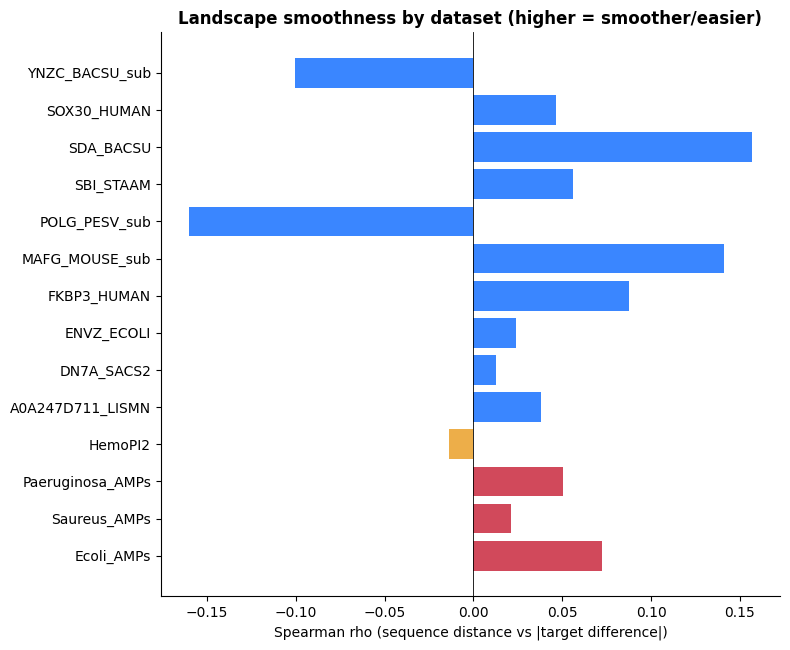

In [4]:
# Bar chart of the ruggedness correlation per dataset (higher = smoother).
if results:
    names = list(results)
    rhos = [results[n][2] for n in names]
    colours = ['#d1495b' if n in ac.AMP_DATASETS else ('#edae49' if n in ac.MINIMIZE_DATASETS else '#3a86ff') for n in names]
    fig, ax = plt.subplots(figsize=(8, 0.4*len(names)+1))
    ax.barh(names, rhos, color=colours)
    ax.axvline(0, color='k', lw=0.6)
    ax.set_xlabel('Spearman rho (sequence distance vs |target difference|)')
    ax.set_title('Landscape smoothness by dataset (higher = smoother/easier)', fontweight='bold')
    fig.tight_layout(); ac.savefig(fig, 'ruggedness_by_dataset'); plt.show()


In [5]:
# Label-discreteness check: how many unique target values, and the smallest gap.
rows = []
for name in targets:
    df = ac.load_dataset(name, files=files)
    if df is None:
        continue
    vals = np.sort(df['score'].unique())
    gaps = np.diff(vals)
    rows.append({'Dataset': name, 'n': len(df), 'n_unique': len(vals),
                 'unique_frac': len(vals)/len(df),
                 'min_gap': float(gaps.min()) if len(gaps) else np.nan})
if rows:
    disc = pd.DataFrame(rows)
    disc.to_csv(os.path.join(ac.FIG_DIR, 'label_discreteness.csv'), index=False)
    print(disc.round(4).to_string(index=False))
    print('\nLow unique_frac or a large min_gap indicates discretised/censored labels, which caps R2.')


         Dataset    n  n_unique  unique_frac  min_gap
      Ecoli_AMPs 3818      1290       0.3379    0.001
    Saureus_AMPs 2644      1008       0.3812    0.001
Paeruginosa_AMPs 2458       851       0.3462    0.001
         HemoPI2 1926       807       0.4190    0.000
A0A247D711_LISMN 1653      1630       0.9861    0.000
      DN7A_SACS2 1008      1008       1.0000    0.000
      ENVZ_ECOLI 1121      1099       0.9804    0.000
     FKBP3_HUMAN 1237      1237       1.0000    0.000
  MAFG_MOUSE_sub 1429      1429       1.0000    0.000
   POLG_PESV_sub 5130      5130       1.0000    0.000
       SBI_STAAM 1025      1025       1.0000    0.000
       SDA_BACSU 2770      2770       1.0000    0.000
     SOX30_HUMAN 1010      1010       1.0000    0.000
  YNZC_BACSU_sub 2300      2300       1.0000    0.000

Low unique_frac or a large min_gap indicates discretised/censored labels, which caps R2.
